# Systemy AI – Laboratorium 4 (wzór)
## Pełny pipeline uczenia maszynowego na przykładzie Titanica

Ten notatnik to **kompletny, działający przykład**. Niczego tu nie musisz pisać: uruchamiaj komórki po kolei, czytaj komentarze i odpowiadaj w myślach na pytania **Sprawdź się** (odpowiedź rozwiniesz kliknięciem).

Twoim zadaniem na tych zajęciach jest zbudowanie **takiego samego pipeline'u** dla zbioru pingwinów w notatniku `SystemyAI_Lab4_Pingwiny.ipynb`. Tam piszesz wszystko sam(a), wzorując się na tym notatniku.

**Przepływ pracy (workflow)**

| Krok | Co robimy | Sekcja |
|---|---|---|
| 1 | Wczytanie danych: `shape`, `head()`, `info()` | 1 |
| 2 | EDA: rozkłady, braki, zależności; usunięcie zbędnych kolumn | 2 |
| 3 | Podział train / test | 3 |
| 4 | Przygotowanie danych: imputacja, kodowanie, skalowanie | 4 |
| 5 | Trenowanie: `model.fit(X_train, y_train)` | 5 |
| 6 | Predykcja: `model.predict(X_test)` | 6 |
| 7 | Ewaluacja na zbiorze testowym | 7 |
| 8 | Iteracja: wracamy i poprawiamy | 8 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

---
## 1. Wczytanie danych

Pierwsze pytania o każdy zbiór: ile jest wierszy i kolumn, jakie są typy, **co przewidujemy** (etykieta) i na podstawie czego (cechy).

In [2]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


Etykieta: `survived` (1 = przeżył/a). To **klasyfikacja binarna**.

---
## 2. EDA – eksploracyjna analiza danych

Najpierw **zrozum dane**, potem modeluj. Szukamy odpowiedzi na pytania:
- czy klasy są zbalansowane? (od tego zależy, czy accuracy coś mówi),
- gdzie są braki i ile ich jest?
- jakie są skale cech? czy rozkłady są skośne?
- które cechy wiążą się z etykietą?

In [4]:
# rozkład etykiety
print(df["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


bill_length_mm       0.6
bill_depth_mm        0.6
flipper_length_mm    0.6
body_mass_g          0.6
sex                  3.2
dtype: float64

In [5]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [6]:
# zależność cech od etykiety
print(df.groupby("species")[num_cols].mean().round(1), "\n")
print(pd.crosstab(df["island"], df["species"]))

           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.0       3700.7
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.5           15.0              217.2       5076.0 

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0


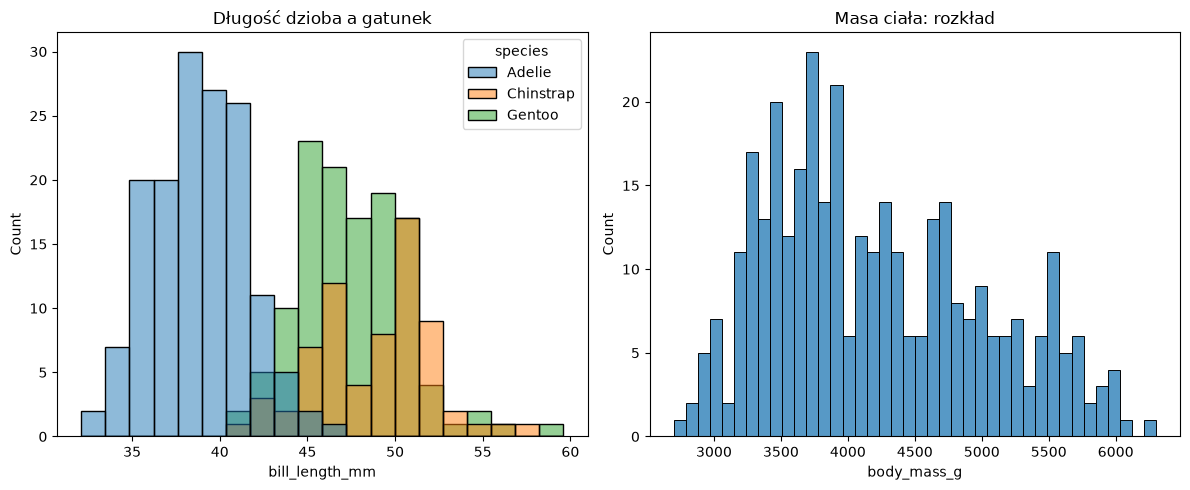

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="bill_length_mm", hue="species", bins=20, ax=axes[0])
axes[0].set_title("Długość dzioba a gatunek")
sns.histplot(data=df, x="body_mass_g", bins=40, ax=axes[1])
axes[1].set_title("Masa ciała: rozkład")
fig.tight_layout()
plt.show()

**Wnioski z EDA, które zmieniają nasze dalsze decyzje:**
- klasy są niezbalansowane (ok. 62% / 38%) → potrzebny **baseline**, a accuracy trzeba porównywać z nim,
- `age` ma ok. 20% braków, `embarked` 2 braki → **imputacja** (`age`: mediana, `embarked`: najczęstsza wartość),
- `fare` jest silnie skośna (skośność ok. 4.8) → do imputacji mediana, nie średnia,
- `sex` i `embarked` są tekstowe → **kodowanie** (one-hot),
- `age` (0–80) i `fare` (0–512) mają różne skale → **standaryzacja**,
- `sex` i `pclass` silnie wiążą się z przeżyciem → to będą ważne cechy.

### Usunięcie zbędnych kolumn

| Kolumna | Dlaczego usuwamy |
|---|---|
| `alive` | to **etykieta zapisana tekstem** (yes/no) – model „widziałby odpowiedź”, czyli wyciek danych |
| `deck` | 77% braków – uzupełnianie byłoby głównie zgadywaniem |
| `class`, `embark_town` | duplikaty `pclass` i `embarked` |
| `who`, `adult_male`, `alone` | cechy wyliczone z innych kolumn; na razie pomijamy (można je dodać przy iteracji) |

In [8]:
df = df.dropna(subset=num_cols, how="all")   # 2 pingwiny bez żadnego pomiaru
print(df.shape)
print(df.columns.tolist())

(342, 7)
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


> **Sprawdź się:** Co by się stało, gdybyśmy zostawili kolumnę `alive`?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Model nauczyłby się, że `alive == 'yes'` oznacza `survived == 1` i miałby accuracy 100% – bez żadnej wartości, bo przy nowym pasażerze tej informacji nie mamy. To klasyczny wyciek danych (*data leakage*).
>
> </details>

---
## 3. Podział train / test

Dzielimy dane **przed** jakimkolwiek krokiem, który uczy się z danych (imputacja, skalowanie, model). Zbiór testowy udaje „nowych pasażerów”.

In [9]:
features = ["island", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"]
target = "species"

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,        # 25% do testu
    stratify=df[target],   # ten sam odsetek każdego gatunku w obu częściach
    random_state=42,       # powtarzalny podział
)
print(X_train.shape, X_test.shape)
print("train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("test: ", y_test.value_counts(normalize=True).round(3).to_dict())

(256, 6) (86, 6)
train: {'Adelie': 0.441, 'Gentoo': 0.359, 'Chinstrap': 0.199}
test:  {'Adelie': 0.442, 'Gentoo': 0.36, 'Chinstrap': 0.198}


> **Sprawdź się:** Po co `stratify`?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Przy losowym podziale odsetek ocalałych w teście mógłby przypadkiem wyjść np. 33% albo 43%. `stratify` gwarantuje te same proporcje klas w obu częściach, więc ocena jest stabilniejsza.
>
> </details>

---
## 4. Przygotowanie danych: jak działa scikit-learn

Każdy obiekt scikit-learn ma ten sam, prosty interfejs:

| Rodzaj | Metody | Przykład |
|---|---|---|
| **estymator** – szacuje parametry z danych | `fit(X)` lub `fit(X, y)` | każdy obiekt poniżej |
| **transformator** – przekształca dane | `transform(X)`, `fit_transform(X)` | `SimpleImputer`, `StandardScaler`, `OneHotEncoder` |
| **predyktor** – przewiduje | `predict(X)`, `score(X, y)` | `LogisticRegression`, `DummyClassifier` |

- **hiperparametry** podajemy w konstruktorze (np. `strategy="median"`) i są dostępne jako atrybuty (`imputer.strategy`),
- **wyuczone parametry** pojawiają się po `fit` i mają **podkreślnik na końcu** (`imputer.statistics_`, `scaler.mean_`).

### 4a. Braki: `SimpleImputer`

In [10]:
imputer = SimpleImputer(strategy="median")   # hiperparametr
imputer.fit(X_train[["bill_length_mm", "body_mass_g"]])        # fit: liczy medianę - TYLKO na train

print("hiperparametr:", imputer.strategy)
print("wyuczone mediany:", imputer.statistics_)        # parametr wyuczony -> podkreślnik

bill_mass_test = imputer.transform(X_test[["bill_length_mm", "body_mass_g"]])   # transform: wstawia TE SAME mediany do testu
print("braki w teście po transform:", np.isnan(bill_mass_test).sum())

hiperparametr: median
wyuczone mediany: [  44.7 4050. ]
braki w teście po transform: 0


### 4b. Kodowanie zmiennych tekstowych: `OneHotEncoder`
Model liczy $w_1 x_1 + w_2 x_2 + \dots$ – tekstu `"male"` nie da się pomnożyć przez wagę:

In [11]:
try:
    LogisticRegression().fit(X_train[["island"]], y_train)
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: 'Dream'


In [12]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(X_train[["island"]].dropna())
print("kategorie:", encoder.categories_)

przyklad = pd.DataFrame({"island": ["Biscoe", "Dream", "Torgersen"]})
pd.DataFrame(encoder.transform(przyklad).toarray(), index=przyklad["island"],
             columns=encoder.get_feature_names_out())

kategorie: [array(['Biscoe', 'Dream', 'Torgersen'], dtype=object)]


,island_Biscoe,island_Dream,island_Torgersen
island,,,
Biscoe,1.0,0.0,0.0
Dream,0.0,1.0,0.0
Torgersen,0.0,0.0,1.0


> **Sprawdź się:** Dlaczego nie zakodować portów jako C = 0, Q = 1, S = 2?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Takie liczby narzucają porządek i równe odstępy: model uznałby, że Q leży „pomiędzy” C i S, a S jest „dwa razy dalej” od C. Port to zmienna nominalna (bez porządku), więc każda kategoria dostaje własną kolumnę 0/1. `pclass` zostawiamy jako liczbę, bo klasy mają naturalny porządek (1 < 2 < 3).
>
> </details>

### 4c. Skalowanie: `StandardScaler`
Wiek (0–80) i cena biletu (0–512) są w różnych skalach. Standaryzacja $x' = (x - \bar{x}) / s$ sprowadza każdą cechę do średniej 0 i odchylenia 1.

In [13]:
# kroki łączą się: wynik imputera (bez braków) trafia do scalera
bill_mass_train = imputer.transform(X_train[["bill_length_mm", "body_mass_g"]])
scaler = StandardScaler().fit(bill_mass_train)        # fit: liczy średnią i odchylenie - TYLKO na train
print("średnie:", scaler.mean_.round(2))              # wyuczone parametry -> podkreślnik
print("odchylenia:", scaler.scale_.round(2))

bill_mass_test_s = scaler.transform(bill_mass_test)    # te same parametry dla testu
print("pierwsze 3 wiersze testu po skalowaniu:\n", bill_mass_test_s[:3].round(2))

średnie: [  44.11 4214.55]
odchylenia: [  5.52 792.68]
pierwsze 3 wiersze testu po skalowaniu:
 [[-0.38 -0.21]
 [-0.33 -0.08]
 [ 1.07  1.87]]


### 4d. Wszystko razem: `ColumnTransformer` + `Pipeline`
Robienie tych kroków ręcznie jest żmudne i łatwo o błąd (np. `fit` na teście). **Pipeline** składa je w jeden estymator:

- `ColumnTransformer` – **różne kroki dla różnych kolumn**: liczby → imputacja medianą + skalowanie, kategorie → imputacja najczęstszą wartością + one-hot,
- `make_pipeline(przygotowanie, model)` – po przygotowaniu dane trafiają do modelu.

Cały pipeline zachowuje się jak jeden model: ma `fit`, `predict` i `score`.

In [14]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]

przygotowanie = ColumnTransformer([
    ("liczby",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                OneHotEncoder(handle_unknown="ignore")),             cat_features),
])

model = make_pipeline(przygotowanie, LogisticRegression())
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('liczby', ...), ('kategorie', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshol

---
## 5. Trenowanie

Jedno `fit` uruchamia po kolei `fit` każdego kroku – **zawsze na danych treningowych**.

In [15]:
model.fit(X_train, y_train)

# inspekcja: wyuczone parametry są dostępne wewnątrz pipeline'u
liczby = model.named_steps["columntransformer"].named_transformers_["liczby"]
print("mediany (z train):", liczby.named_steps["simpleimputer"].statistics_)

nazwy = model.named_steps["columntransformer"].get_feature_names_out()
lr = model.named_steps["logisticregression"]
wagi = pd.DataFrame(lr.coef_.T, index=nazwy, columns=lr.classes_)   # 3 klasy -> osobne wagi dla każdego gatunku
wagi.round(3)

mediany (z train): [  44.7   17.4  197.  4050. ]


,Adelie,Chinstrap,Gentoo
liczby__bill_length_mm,-2.244,1.855,0.388
liczby__bill_depth_mm,0.975,0.354,-1.330
liczby__flipper_length_mm,-0.681,-0.272,0.953
liczby__body_mass_g,-0.045,-0.863,0.908
kategorie__island_Biscoe,0.078,-0.700,0.622
kategorie__island_Dream,-0.603,1.083,-0.480
kategorie__island_Torgersen,0.525,-0.380,-0.145
kategorie__sex_Female,-0.566,0.407,0.159
kategorie__sex_Male,0.567,-0.404,-0.163


> **Sprawdź się:** Która cecha najbardziej zwiększa, a która najbardziej zmniejsza szansę przeżycia?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Największa dodatnia waga: `sex_female`, największe ujemne: `sex_male` i `pclass` (wyższy numer klasy = gorzej). Zgadza się z EDA. Porównywanie wag ma sens, bo cechy liczbowe są wystandaryzowane.
>
> </details>

---
## 6. Predykcja

`predict` przepuszcza nowe dane przez **te same kroki z zapamiętanymi parametrami** (mediany i średnie z train) i zwraca decyzje. `predict_proba` zwraca prawdopodobieństwa.

In [16]:
y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

podglad = X_test.head(5).copy()
for i, gatunek in enumerate(model.classes_):
    podglad[f"p({gatunek})"] = proba[:5, i].round(2)
podglad["predykcja"] = y_pred[:5]
podglad["prawda"] = y_test.head(5).values
podglad

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,p(Adelie),p(Chinstrap),p(Gentoo),predykcja,prawda
53,Biscoe,42.0,19.5,200.0,4050.0,Male,0.99,0.01,0.0,Adelie,Adelie
49,Dream,42.3,21.2,191.0,4150.0,Male,0.97,0.03,0.0,Adelie,Adelie
221,Biscoe,50.0,16.3,230.0,5700.0,Male,0.00,0.00,1.0,Gentoo,Gentoo
317,Biscoe,46.9,14.6,222.0,4875.0,Female,0.00,0.00,1.0,Gentoo,Gentoo
93,Dream,39.6,18.1,186.0,4450.0,Male,0.99,0.01,0.0,Adelie,Adelie


---
## 7. Ewaluacja

`score(X, y)` to szybka ocena: **dla klasyfikatora zwraca accuracy**, dla regresora $R^2$. Zawsze porównujemy z **baseline'em**: `DummyClassifier` to „model”, który zawsze zwraca najczęstszą klasę – ma ten sam interfejs co każdy estymator.

In [17]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

# prosta reguła z EDA: długa płetwa -> Gentoo, długi dziób -> Chinstrap, reszta -> Adelie
regula = np.where(X_test["flipper_length_mm"] > 206, "Gentoo",
                  np.where(X_test["bill_length_mm"] > 43, "Chinstrap", "Adelie"))

wyniki = pd.Series({
    "baseline (zawsze Adelie)": baseline.score(X_test, y_test),
    "reguła: płetwa/dziób": (regula == y_test).mean(),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
wyniki.round(3)

baseline (zawsze Adelie)    0.442
reguła: płetwa/dziób        0.988
pipeline – train            0.996
pipeline – test             1.000
dtype: float64

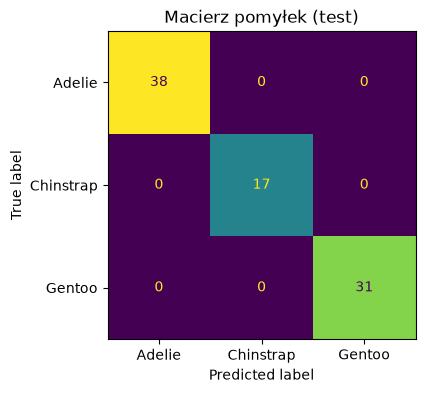

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [18]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=model.classes_).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek (test)")
plt.show()

print(classification_report(y_test, y_pred, digits=3))

> **Sprawdź się:** Wynik na train jest wyższy niż na test. Który raportujemy i dlaczego?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Wynik testowy (ok. 0.77). Model widział dane treningowe, więc ocena na nich jest zawyżona. Test udaje nowe dane – tylko on mówi, jak model poradzi sobie w praktyce.
>
> </details>

> **Sprawdź się:** Pipeline jest lepszy od reguły „kobieta → 1” tylko o ok. 0.5 p.p. Co z tego wynika?
>
> <details><summary>pokaż odpowiedź</summary>
>
> W zbiorze testowym (223 osoby) to różnica jednej osoby, czyli w granicach przypadku. Na tych danych model w dużej mierze „odkrył” regułę płci. Wniosek: zawsze porównujemy z prostymi punktami odniesienia, a nie tylko z zerem.
>
> </details>

---
## 8. Iteracja

Pipeline ułatwia eksperymenty: zmieniamy jeden element i sprawdzamy efekt **na tym samym podziale**. Tu sprawdzamy dwa pomysły:
- `SimpleImputer(..., add_indicator=True)` – dodaje kolumnę-flagę „wiek był brakujący”,
- model **bez płci** – jak ważna jest ta jedna cecha?

In [19]:
def zbuduj(num, cat, add_indicator=False):
    przyg = ColumnTransformer([
        ("liczby", make_pipeline(SimpleImputer(strategy="median", add_indicator=add_indicator), StandardScaler()), num),
        ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat),
    ])
    return make_pipeline(przyg, LogisticRegression())


warianty = {
    "pełny": zbuduj(num_features, cat_features),
    "+ flaga braków": zbuduj(num_features, cat_features, add_indicator=True),
    "bez płci": zbuduj(num_features, ["island"]),
}
pd.Series({nazwa: m.fit(X_train, y_train).score(X_test, y_test) for nazwa, m in warianty.items()}).round(3)

pełny             1.0
+ flaga braków    1.0
bez płci          1.0
dtype: float64

> **Sprawdź się:** Czy wybieranie najlepszego wariantu po wyniku na zbiorze testowym jest w porządku?
>
> <details><summary>pokaż odpowiedź</summary>
>
> Nie do końca: jeśli porównamy wiele wariantów i wybierzemy najlepszy na teście, to test przestaje być „nowymi danymi” – dopasowaliśmy decyzję do niego. Poprawnie robi się to na osobnym zbiorze walidacyjnym albo walidacją krzyżową (kolejne zajęcia). Test zostawiamy na samą końcową ocenę.
>
> </details>

---
## Podsumowanie: lista kontrolna do zadania z pingwinami

1. Wczytaj dane, sprawdź `shape`, `info()`, wybierz etykietę.
2. EDA: rozkład klas, braki, skale, zależności (tabela, wykres). Zapisz wnioski i decyzje.
3. Usuń to, co zbędne (wiersze/kolumny) i **uzasadnij**.
4. Podział train/test **przed** przygotowaniem danych (`stratify`, `random_state`).
5. `ColumnTransformer`: liczby → imputer + scaler, kategorie → imputer + one-hot.
6. `make_pipeline(przygotowanie, model)`, `fit` na train.
7. Ewaluacja na test: `score`, baseline (`DummyClassifier`), macierz pomyłek, `classification_report`.
8. Iteracja: zmień jedną rzecz i porównaj.